# Experiment 3: Implementation of the Bernstein-Vazirani Algorithm Using Qiskit

**Course:** Quantum Computing and Algorithms  
**Name:** Ritesh Roshan Sahoo  
**Roll Number:** DL.AI.U4AID24036  
**Email:** riteshroshansahoo01@gmail.com

## Aim

To implement and experimentally investigate the Bernstein-Vazirani algorithm using Qiskit for determining a hidden binary string with a single oracle query.

## Setup

In [1]:
%pip install --quiet qiskit qiskit-aer matplotlib pylatexenc

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

backend = AerSimulator()

## Task 1: Basic Bernstein-Vazirani Implementation

### Problem Statement

Consider the hidden string $s = 1011$ and the oracle $f(x) = s \cdot x \pmod 2$. Implement the complete Bernstein-Vazirani circuit (ancilla in $|-\rangle$, Hadamards, oracle, Hadamards, measurement of the input register) and recover $s$ with a single oracle query.

Qiskit prints a classical register with bit 0 on the right, so the oracle is wired from the right-most character of $s$ to qubit 0. The measured string then reads exactly as $s$ is written.

### Program

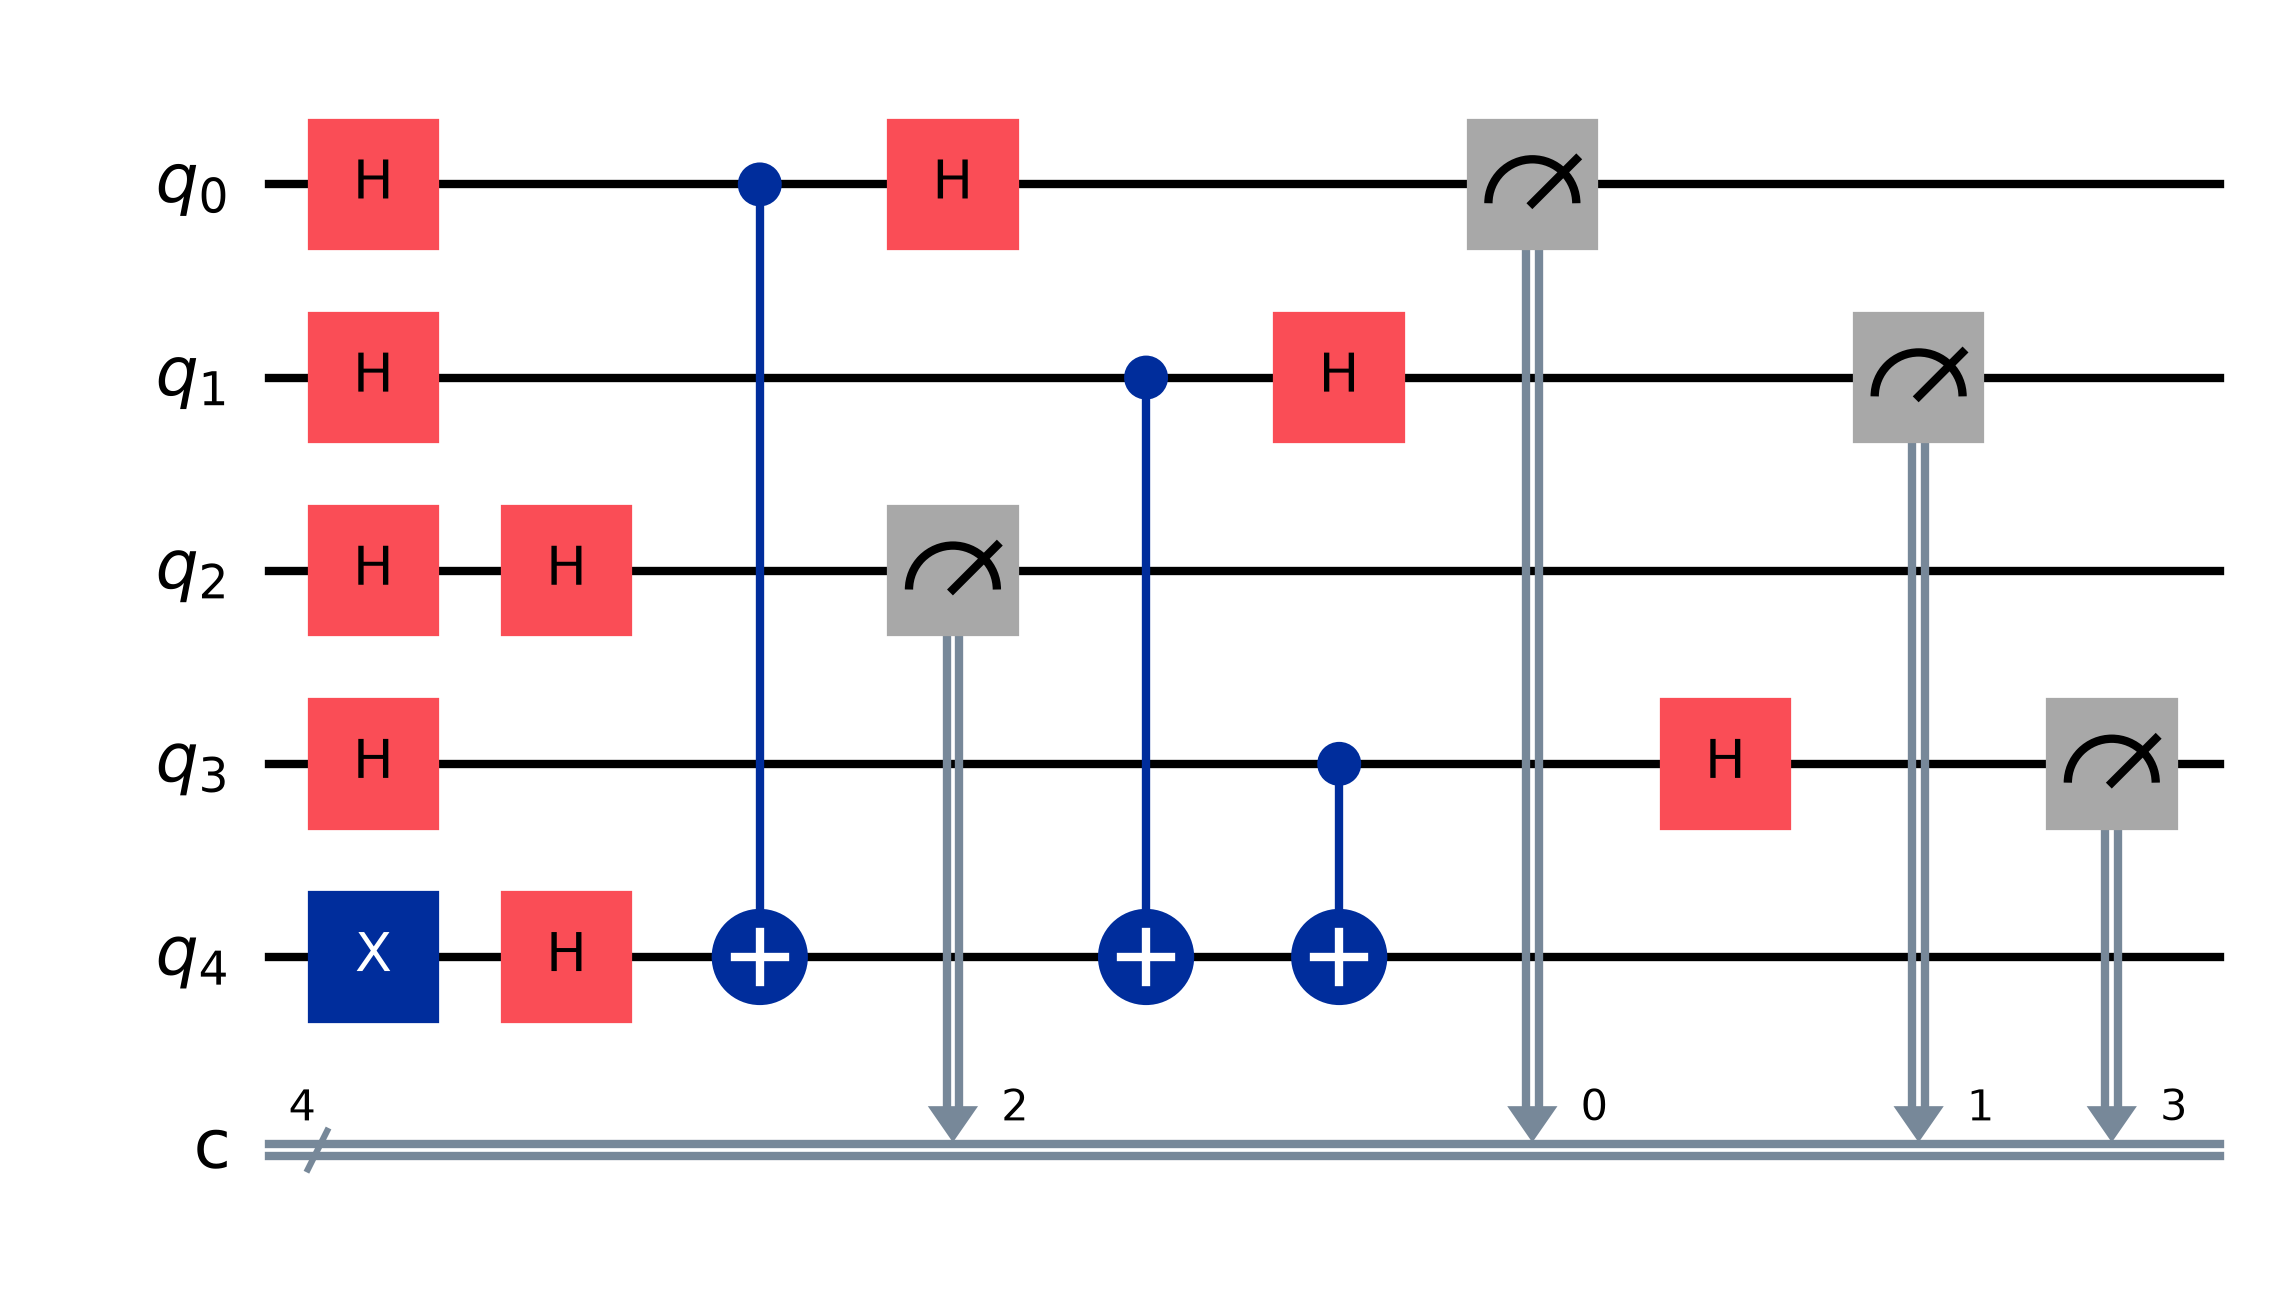

Measurement Results: {'1011': 1024}


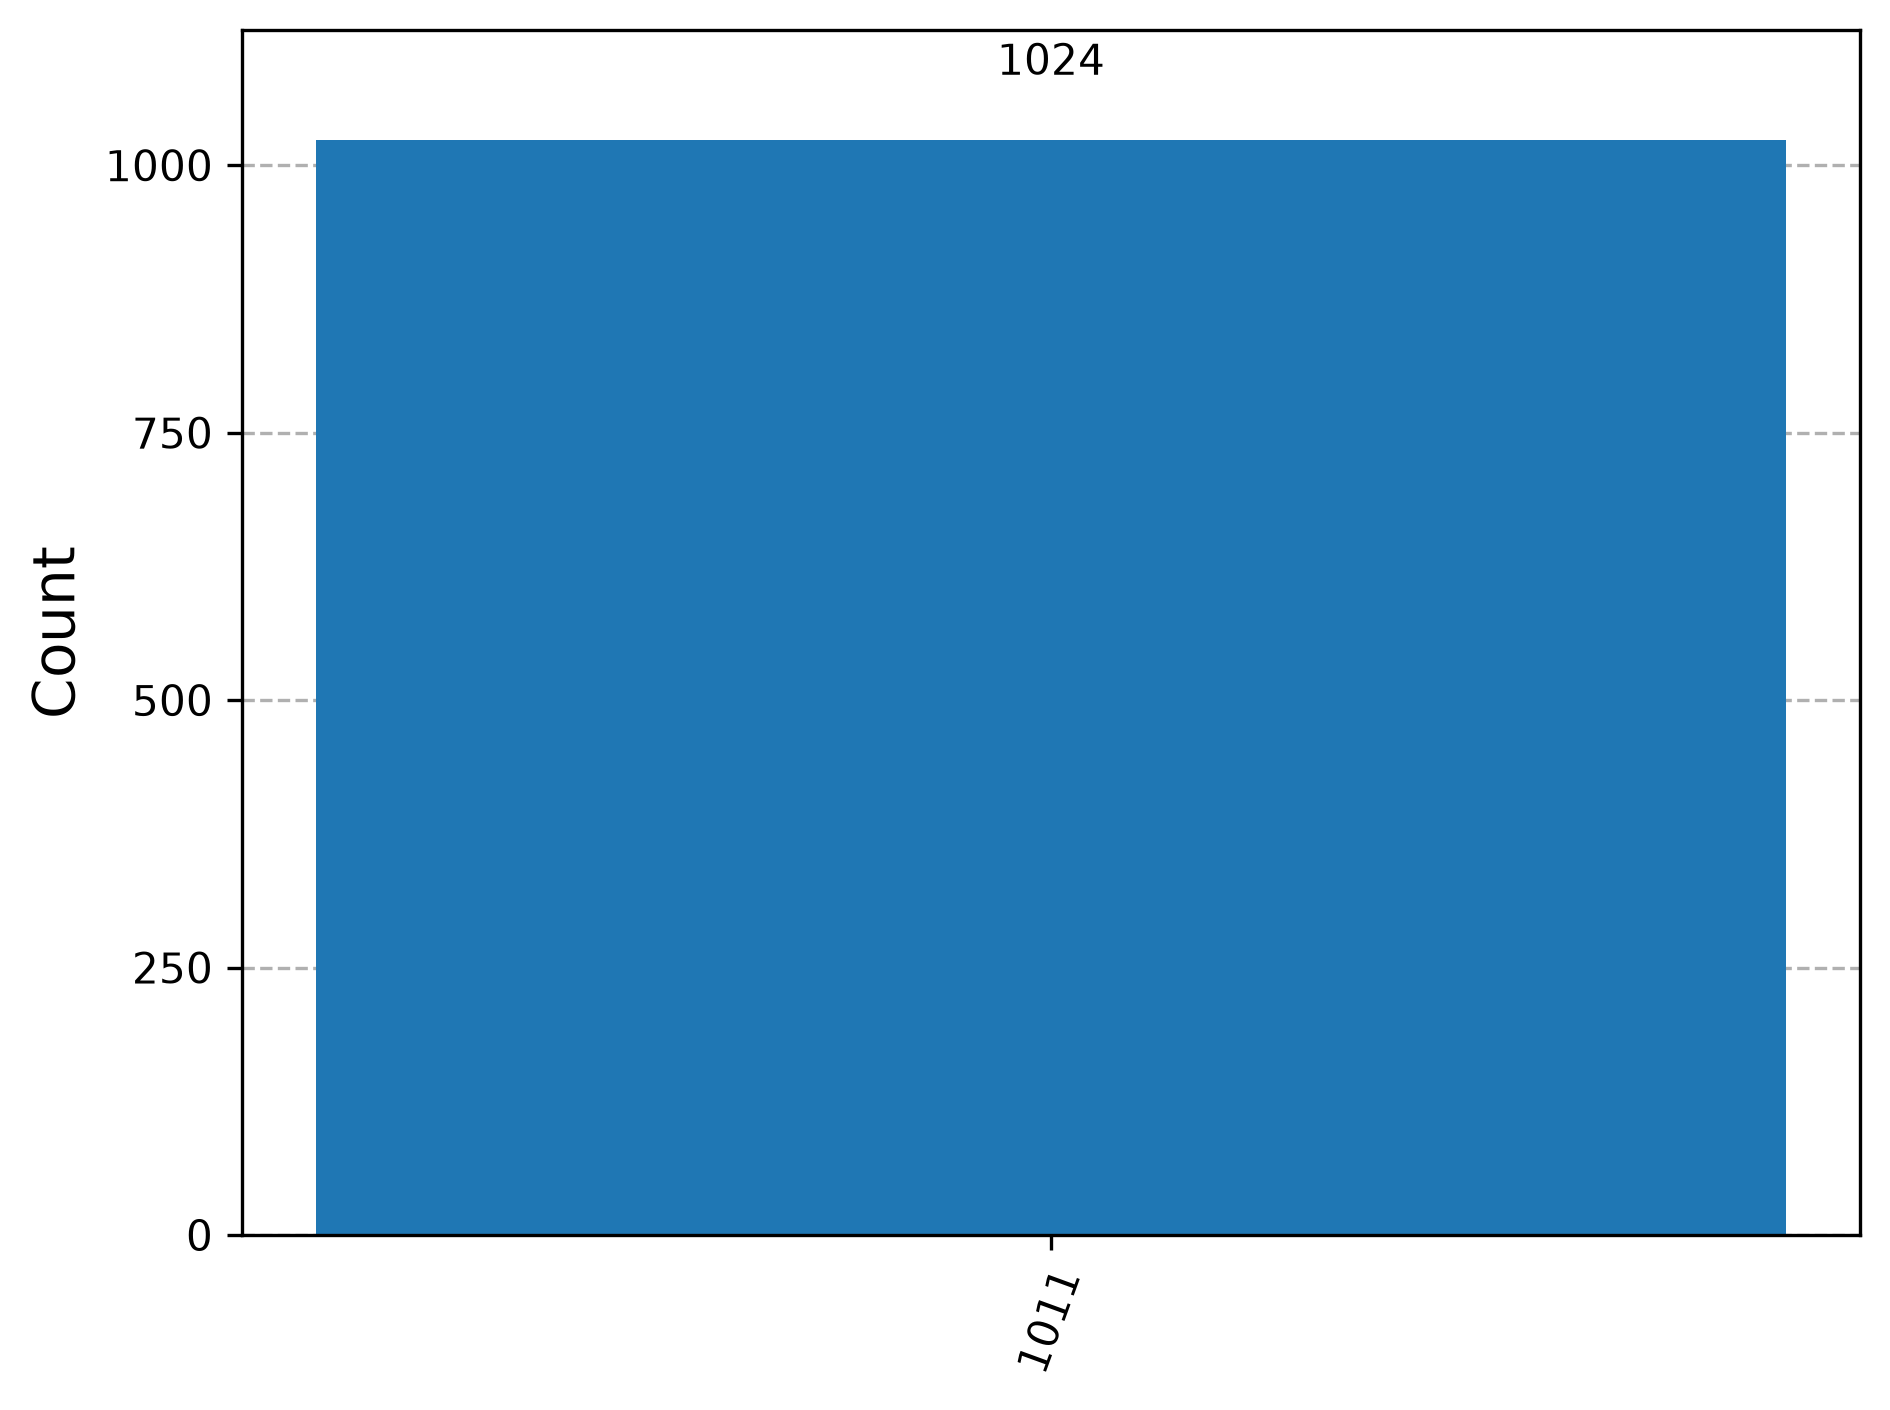

In [3]:
# Hidden string
s = "1011"
n = len(s)

# n input qubits + 1 ancilla
qc = QuantumCircuit(n + 1, n)

# Prepare ancilla |1>
qc.x(n)

# Hadamard on all qubits
qc.h(range(n + 1))

# Bernstein-Vazirani Oracle (qubit i holds bit i from the right)
for i, bit in enumerate(reversed(s)):
    if bit == "1":
        qc.cx(i, n)

# Final Hadamard on input register
qc.h(range(n))

# Measurement
qc.measure(range(n), range(n))

display(qc.draw("mpl"))

# Simulation
compiled = transpile(qc, backend)
result = backend.run(compiled, shots=1024).result()
counts = result.get_counts()

print("Measurement Results:", counts)
display(plot_histogram(counts))

### Observation

The only measured outcome is **1011 on all 1024 shots**, so the hidden string is recovered with certainty from **one oracle query**. The oracle is a CX from every input qubit whose bit of $s$ is 1 onto the ancilla; with the ancilla in $|-\rangle$ each CX kicks a phase $(-1)^{x_i}$ back onto the input, and the final Hadamards convert the phase pattern into the bit string $s$.

## Task 2: Hidden Oracle / Reverse Engineering

### Problem Statement

Recover an unknown hidden string without being told its value. The oracle is generated internally from an instructor-defined string that the circuit builder does not inspect. Report the recovered string, the number of oracle queries, whether another circuit could represent the same function and whether the physical oracle is unique.

### Program

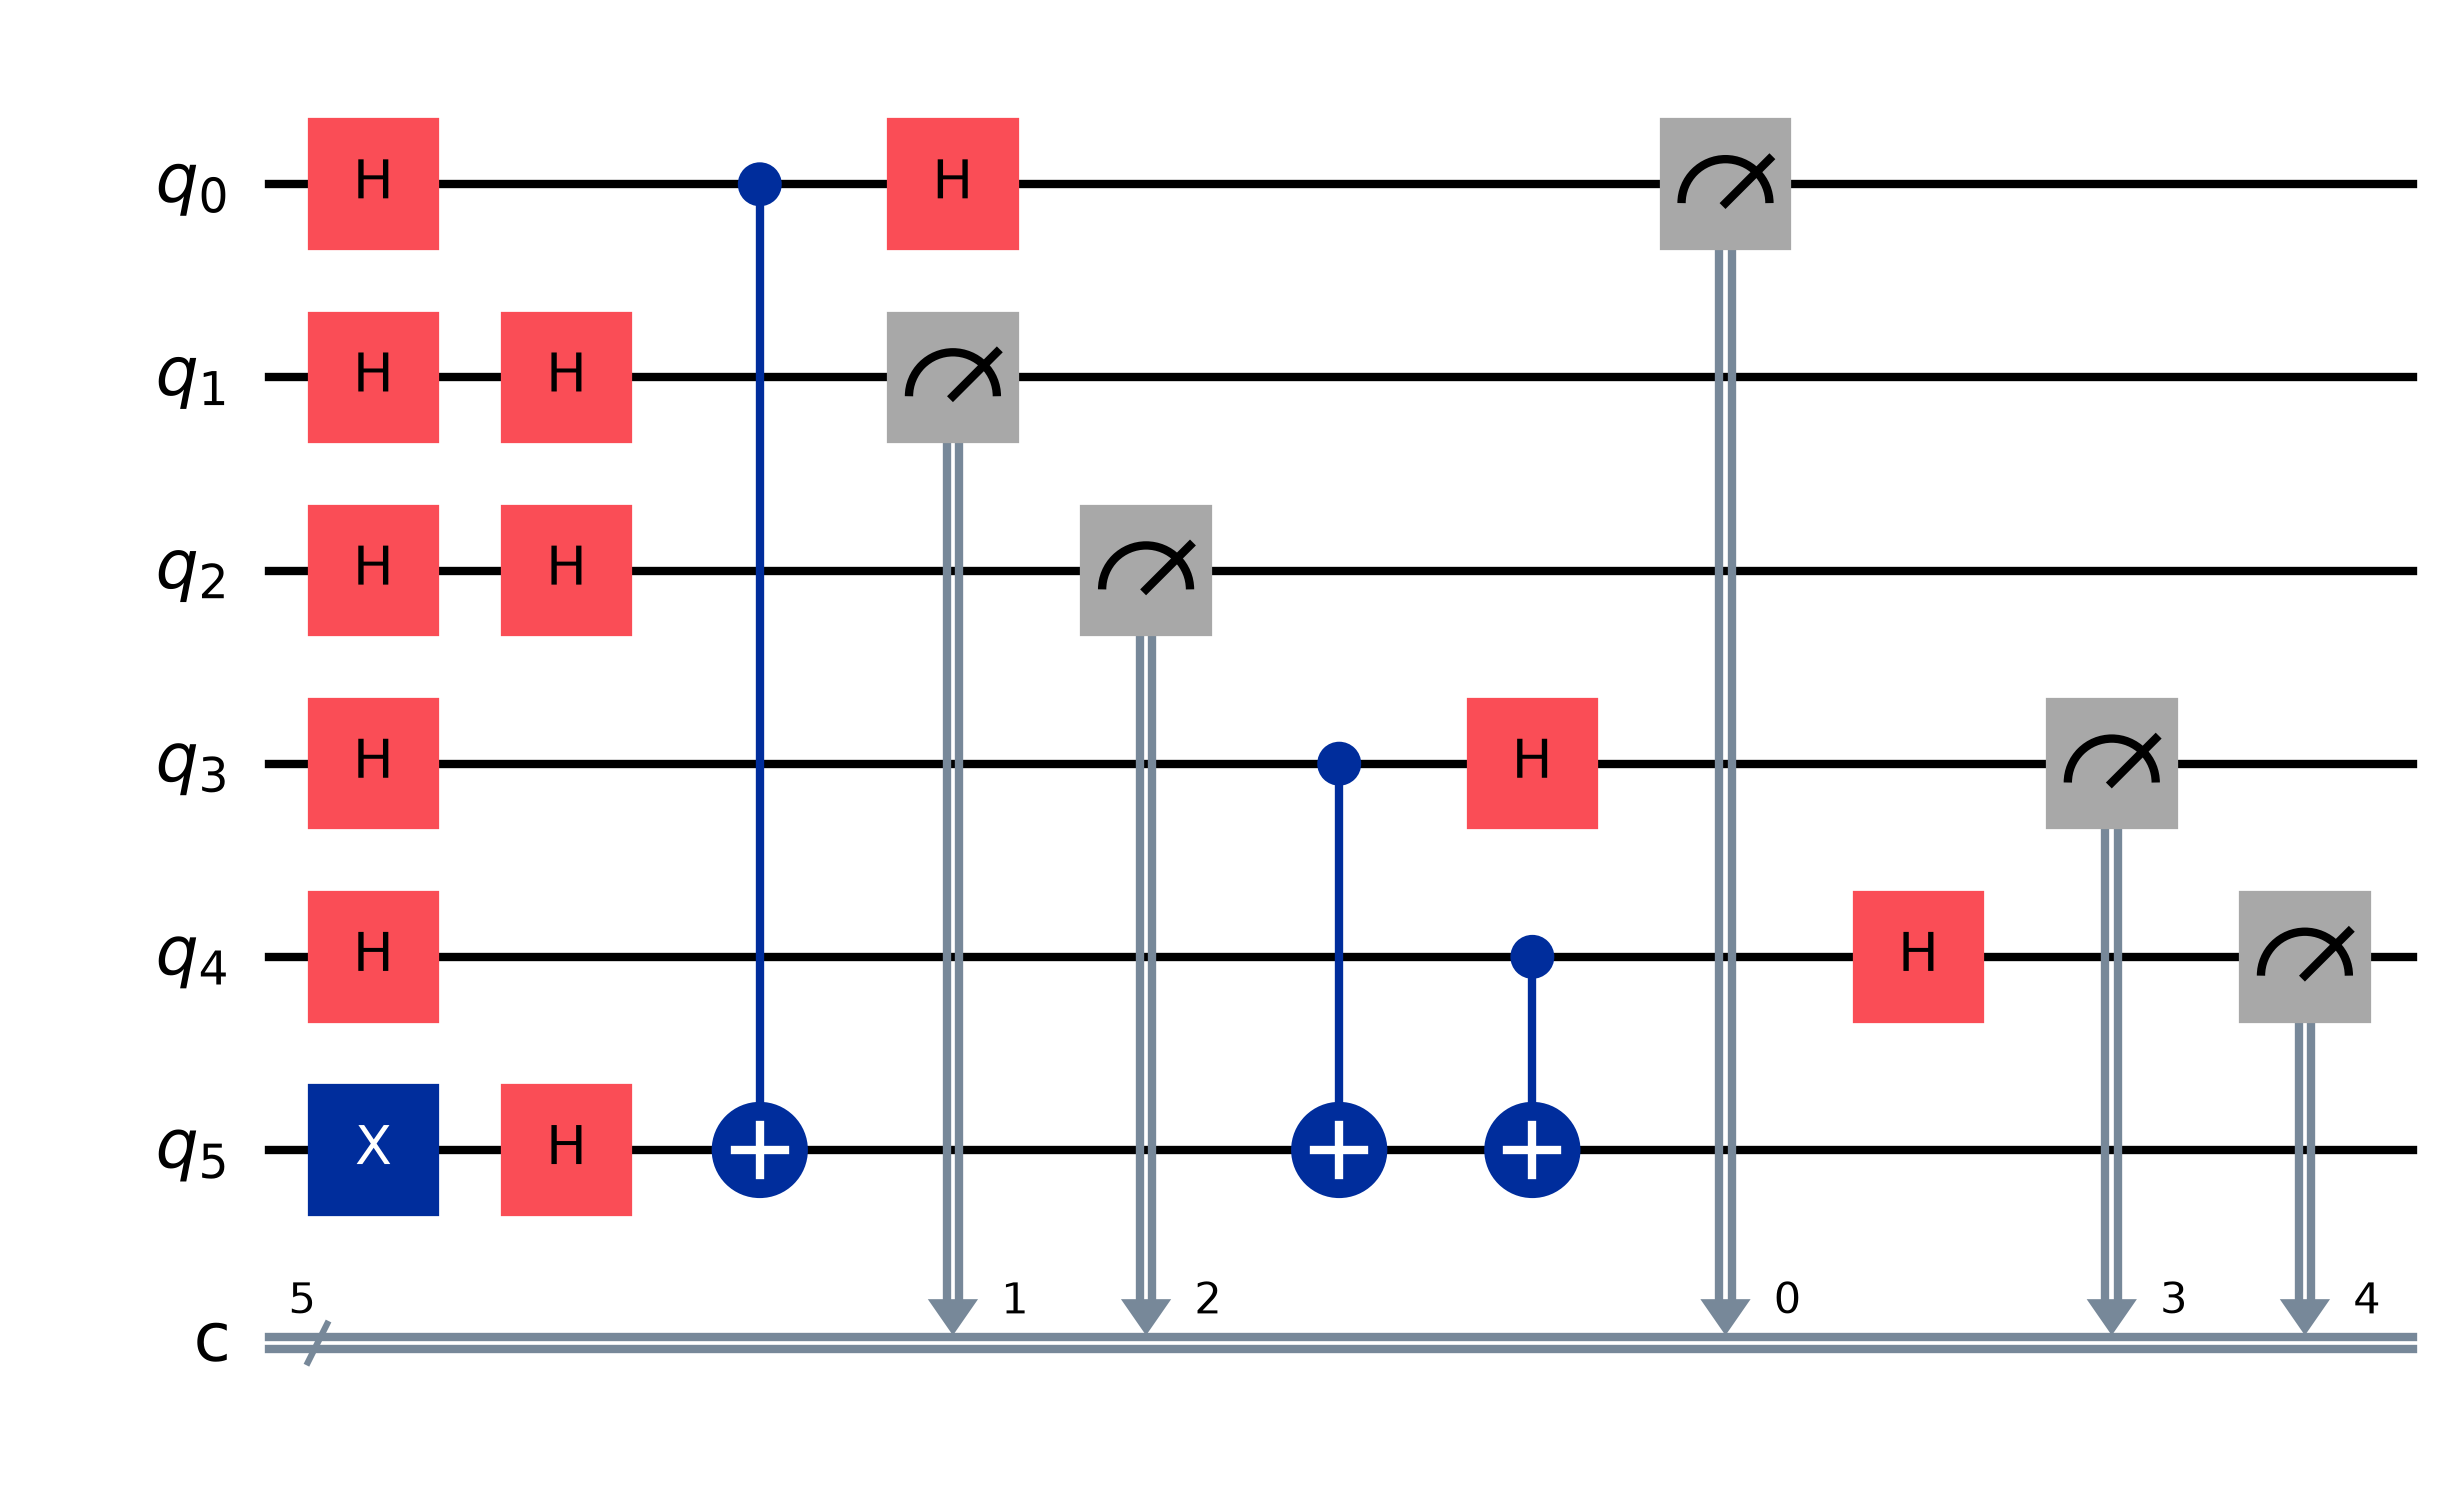

Recovered string: 11001
Counts: {'11001': 1024}
Oracle queries used: 1


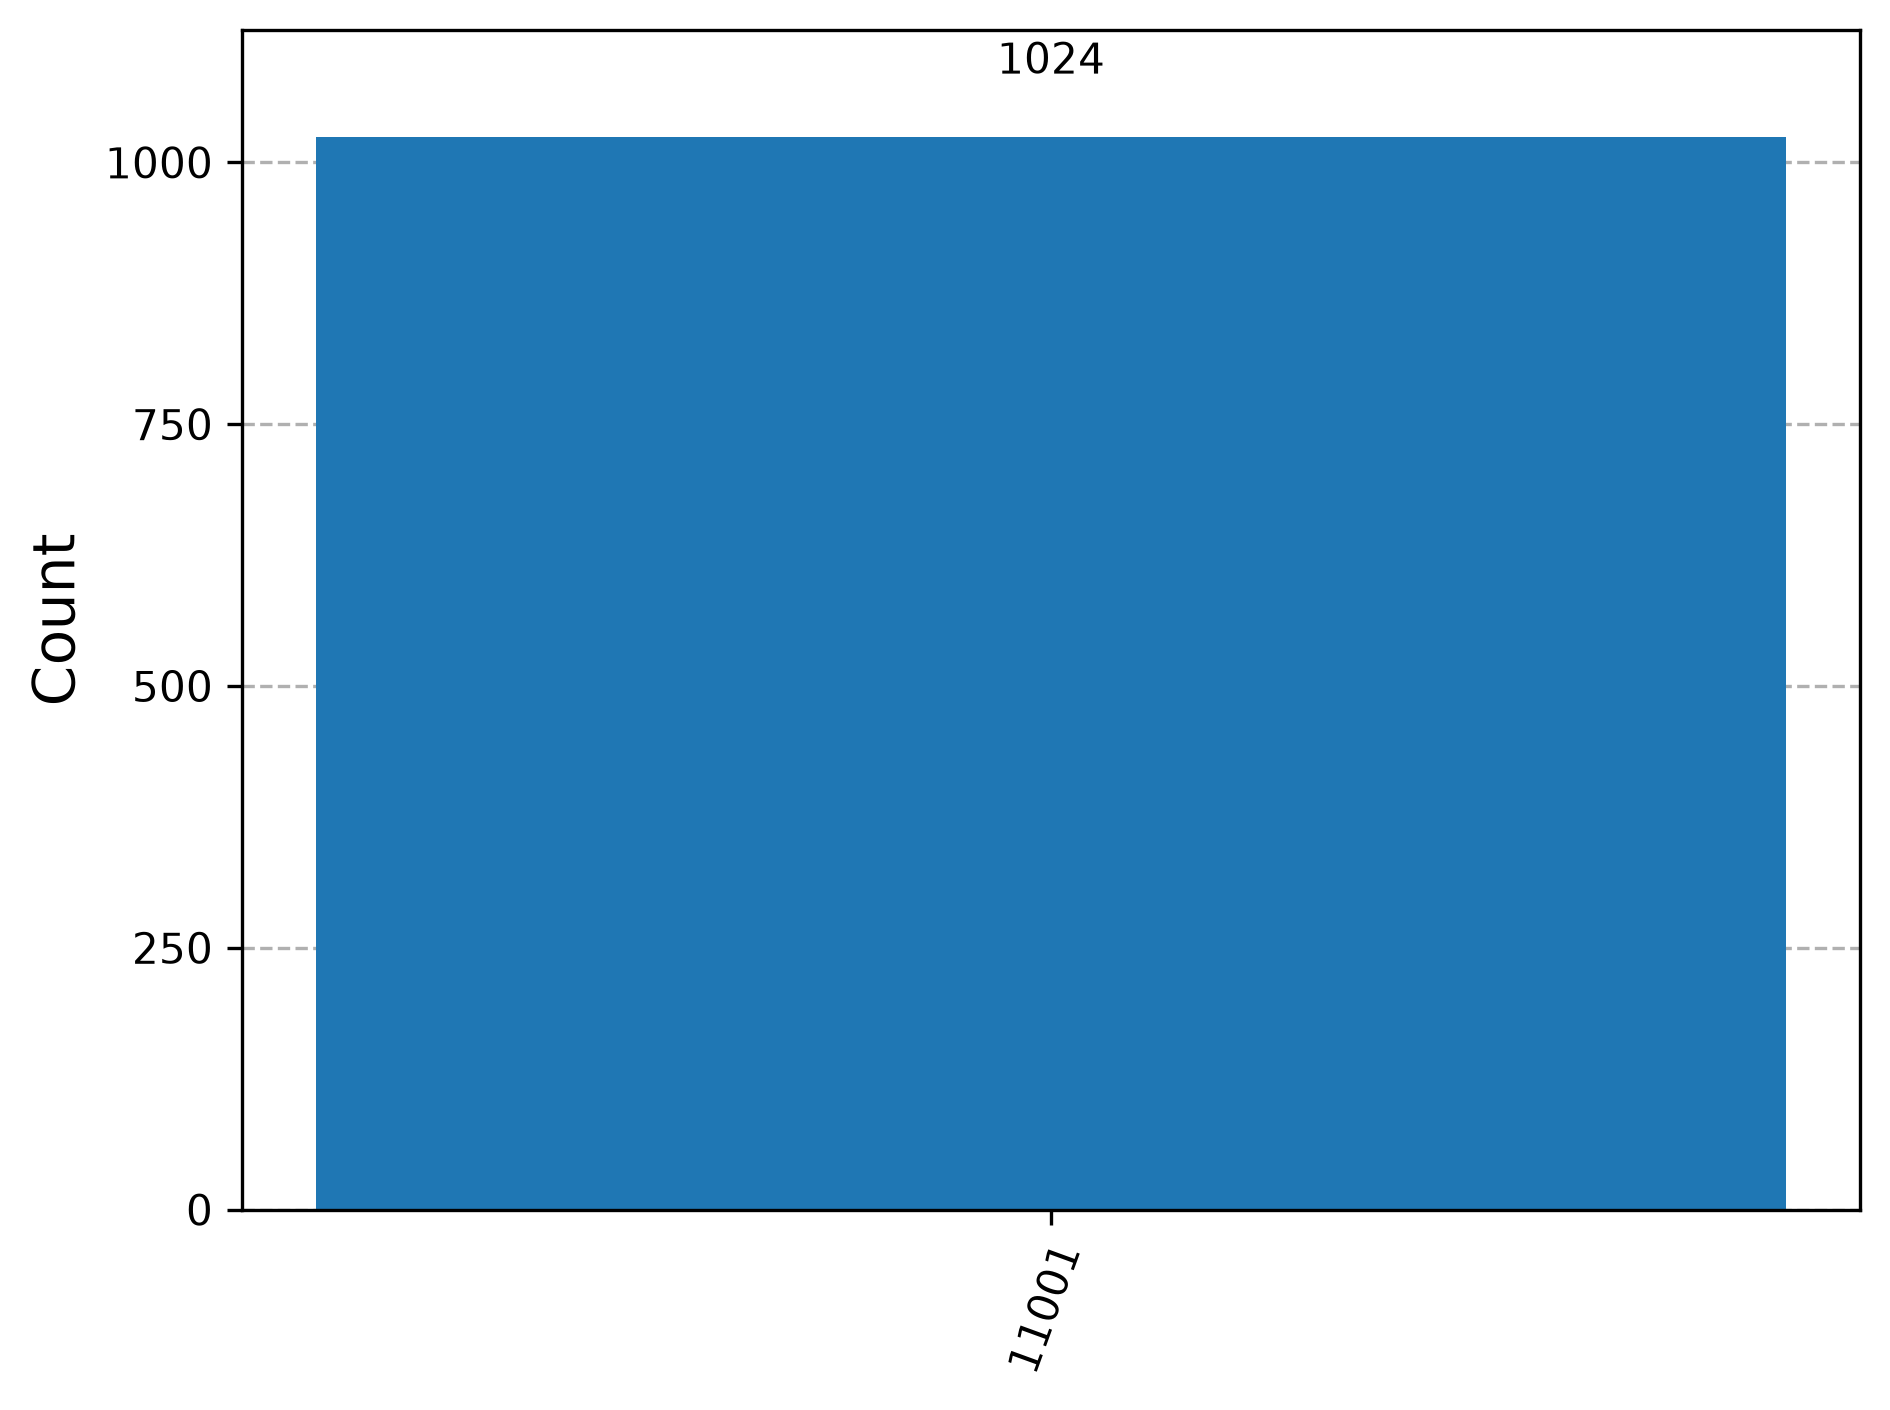

In [4]:
# Instructor-defined hidden string (not inspected below)
hidden_string = "11001"
n = len(hidden_string)

def bv_oracle(qc, s):
    for i, bit in enumerate(reversed(s)):
        if bit == "1":
            qc.cx(i, n)

qc = QuantumCircuit(n + 1, n)

# Ancilla |1>
qc.x(n)

# Initial superposition
qc.h(range(n + 1))

# Unknown oracle
bv_oracle(qc, hidden_string)

# Interference
qc.h(range(n))

# Measurement
qc.measure(range(n), range(n))

display(qc.draw("mpl"))

result = backend.run(
    transpile(qc, backend), shots=1024
).result()
counts = result.get_counts()

print("Recovered string:", max(counts, key=counts.get))
print("Counts:", counts)
print("Oracle queries used: 1")
display(plot_histogram(counts))

In [5]:
# Is the oracle unique? Two circuits for the same f(x) = s.x
from qiskit.quantum_info import Operator

oracle_A = QuantumCircuit(n + 1)
bv_oracle(oracle_A, hidden_string)

# Same function with the CX gates applied in reverse order
oracle_B = QuantumCircuit(n + 1)
for i, bit in reversed(list(enumerate(reversed(hidden_string)))):
    if bit == "1":
        oracle_B.cx(i, n)

print("Same unitary:", Operator(oracle_A).equiv(Operator(oracle_B)))

Same unitary: True


### Observation

- **Recovered string**: 11001, measured on every shot.
- **Oracle queries**: one, regardless of the string length.
- **Another circuit for the same function**: yes. The CX gates commute, so any ordering, or any other circuit with the same unitary, represents the same Boolean function; the two orderings tested have identical unitaries.
- **Is the physical oracle unique?** No. The function $f(x) = s \cdot x$ fixes the unitary, not the gate sequence that realises it.

## Task 3: Classical vs Quantum Query Complexity

### Problem Statement

For $f(x) = s \cdot x \pmod 2$, determine the hidden string classically (one query per basis input $100\ldots0$, $010\ldots0$, and so on) and with the Bernstein-Vazirani algorithm, for $n = 2, 3, 4, 5, 6$, and compare the number of oracle queries.

### Program

In [6]:
def classical_recovery(hidden_string):
    n = len(hidden_string)
    recovered = []
    for i in range(n):
        # Query corresponding basis input
        x = [0] * n
        x[i] = 1
        # f(x) gives the ith bit of s
        value = hidden_string[i]
        recovered.append(value)
    return "".join(recovered)

def bv_circuit(s):
    n = len(s)
    qc = QuantumCircuit(n + 1, n)
    qc.x(n)
    qc.h(range(n + 1))
    for i, bit in enumerate(reversed(s)):
        if bit == "1":
            qc.cx(i, n)
    qc.h(range(n))
    qc.measure(range(n), range(n))
    return qc

print("n  classical queries  quantum queries  classical  quantum")
for n in range(2, 7):
    s = "1" * n
    classical = classical_recovery(s)
    counts = backend.run(
        transpile(bv_circuit(s), backend), shots=1024
    ).result().get_counts()
    quantum = max(counts, key=counts.get)
    print(f"{n}  {n:>17}  {1:>15}  {classical:>9}  {quantum:>7}")

n  classical queries  quantum queries  classical  quantum
2                  2                1         11       11


3                  3                1        111      111


4                  4                1       1111     1111
5                  5                1      11111    11111


6                  6                1     111111   111111


### Observation

| Number of input bits | Classical queries | Quantum queries |
| --- | --- | --- |
| 2 | 2 | 1 |
| 3 | 3 | 1 |
| 4 | 4 | 1 |
| 5 | 5 | 1 |
| 6 | 6 | 1 |
*Classical and quantum query comparison*

Both methods recover the string every time, but the classical method needs **one query per bit**, $O(n)$, while the quantum circuit needs **one query for any $n$**, $O(1)$. The quantum circuit does grow with $n$ in gates and depth, so the advantage is in oracle queries, not in total circuit size.

## Task 4: Phase Kickback Investigation

### Problem Statement

The standard algorithm prepares the ancilla in $|-\rangle$. Run the circuit for $s = 101$ with the ancilla prepared as $|0\rangle$, $|1\rangle$, $|+\rangle$ and $|-\rangle$, compare the statevectors after the oracle and the measurement results, and identify which preparation produces phase kickback.

### Program

In [7]:
s = "101"
n = len(s)

def create_bv_circuit(ancilla_state):
    qc = QuantumCircuit(n + 1)
    # Prepare ancilla
    if ancilla_state == "|1>":
        qc.x(n)
    elif ancilla_state == "|+>":
        qc.h(n)
    elif ancilla_state == "|->":
        qc.x(n)
        qc.h(n)
    # Input register
    qc.h(range(n))
    # Oracle
    for i, bit in enumerate(reversed(s)):
        if bit == "1":
            qc.cx(i, n)
    return qc

states = ["|0>", "|1>", "|+>", "|->"]

for ancilla in states:
    qc = create_bv_circuit(ancilla)
    state = Statevector.from_instruction(qc)
    print("\nAncilla:", ancilla)
    print(qc.draw())
    print("Statevector after oracle:")
    print(np.round(state.data, 3))

    # Finish the algorithm and measure the input register
    qc.h(range(n))
    qc.measure_all()
    counts = backend.run(
        transpile(qc, backend), shots=1024
    ).result().get_counts()
    print("Counts (ancilla bit on the left):", counts)


Ancilla: |0>
     ┌───┐          
q_0: ┤ H ├──■───────
     ├───┤  │       
q_1: ┤ H ├──┼───────
     ├───┤  │       
q_2: ┤ H ├──┼────■──
     └───┘┌─┴─┐┌─┴─┐
q_3: ─────┤ X ├┤ X ├
          └───┘└───┘
Statevector after oracle:
[0.354+0.j 0.   +0.j 0.354+0.j 0.   +0.j 0.   +0.j 0.354+0.j 0.   +0.j
 0.354+0.j 0.   +0.j 0.354+0.j 0.   +0.j 0.354+0.j 0.354+0.j 0.   +0.j
 0.354+0.j 0.   +0.j]


Counts (ancilla bit on the left): {'0000': 232, '1000': 256, '1101': 282, '0101': 254}

Ancilla: |1>
     ┌───┐          
q_0: ┤ H ├──■───────
     ├───┤  │       
q_1: ┤ H ├──┼───────
     ├───┤  │       
q_2: ┤ H ├──┼────■──
     ├───┤┌─┴─┐┌─┴─┐
q_3: ┤ X ├┤ X ├┤ X ├
     └───┘└───┘└───┘
Statevector after oracle:
[0.   +0.j 0.354+0.j 0.   +0.j 0.354+0.j 0.354+0.j 0.   +0.j 0.354+0.j
 0.   +0.j 0.354+0.j 0.   +0.j 0.354+0.j 0.   +0.j 0.   +0.j 0.354+0.j
 0.   +0.j 0.354+0.j]


Counts (ancilla bit on the left): {'0101': 279, '1000': 248, '0000': 248, '1101': 249}

Ancilla: |+>
     ┌───┐          
q_0: ┤ H ├──■───────
     ├───┤  │       
q_1: ┤ H ├──┼───────
     ├───┤  │       
q_2: ┤ H ├──┼────■──
     ├───┤┌─┴─┐┌─┴─┐
q_3: ┤ H ├┤ X ├┤ X ├
     └───┘└───┘└───┘
Statevector after oracle:
[0.25+0.j 0.25+0.j 0.25+0.j 0.25+0.j 0.25+0.j 0.25+0.j 0.25+0.j 0.25+0.j
 0.25+0.j 0.25+0.j 0.25+0.j 0.25+0.j 0.25+0.j 0.25+0.j 0.25+0.j 0.25+0.j]


Counts (ancilla bit on the left): {'1000': 534, '0000': 490}

Ancilla: |->
     ┌───┐               
q_0: ┤ H ├───────■───────
     ├───┤       │       
q_1: ┤ H ├───────┼───────
     ├───┤       │       
q_2: ┤ H ├───────┼────■──
     ├───┤┌───┐┌─┴─┐┌─┴─┐
q_3: ┤ X ├┤ H ├┤ X ├┤ X ├
     └───┘└───┘└───┘└───┘
Statevector after oracle:
[ 0.25+0.j -0.25+0.j  0.25+0.j -0.25+0.j -0.25+0.j  0.25+0.j -0.25+0.j
  0.25+0.j -0.25+0.j  0.25+0.j -0.25+0.j  0.25+0.j  0.25+0.j -0.25+0.j
  0.25+0.j -0.25+0.j]
Counts (ancilla bit on the left): {'0101': 504, '1101': 520}


### Observation

| Ancilla | Amplitudes after the oracle | Measured input register | Phase kickback? |
| --- | --- | --- | --- |
| $|0\rangle$ | all positive, ancilla entangled with input | 000 or 101, each half the time | No |
| $|1\rangle$ | all positive, ancilla entangled with input | 000 or 101, each half the time | No |
| $|+\rangle$ | all positive, product state | always 000 | No |
| $|-\rangle$ | signs follow $(-1)^{s \cdot x}$ | always 101 | **Yes** |
*Ancilla preparations for s = 101*

Only the **$|-\rangle$ ancilla produces phase kickback**: the oracle leaves the ancilla alone and multiplies each input state by $(-1)^{s \cdot x}$, which the final Hadamards turn into $|s\rangle$. With $|0\rangle$ or $|1\rangle$ the oracle writes $f(x)$ into the ancilla instead, entangling it with the input, and the input register collapses to $000$ or $101$ at random, so a single run cannot be trusted. With $|+\rangle$ the CX gates have no effect at all, and the circuit returns $000$.

## Task 5: Noise, Scalability and Circuit Optimization

### Problem Statement

Run the Bernstein-Vazirani algorithm on an ideal simulator and on a noisy simulator (depolarizing error of 1 percent on single-qubit gates and 3 percent on CX) for hidden strings of length $n = 2, 3, 4, 5, 6$. Record qubits, depth, gate count, ideal accuracy and noisy accuracy, and study the effect of transpiler optimisation.

### Program

Ideal: {'10101': 1024}
Noisy: {'10101': 929, '10100': 13, '00101': 29, '10001': 18, '00000': 18, '10000': 4, '00001': 13}


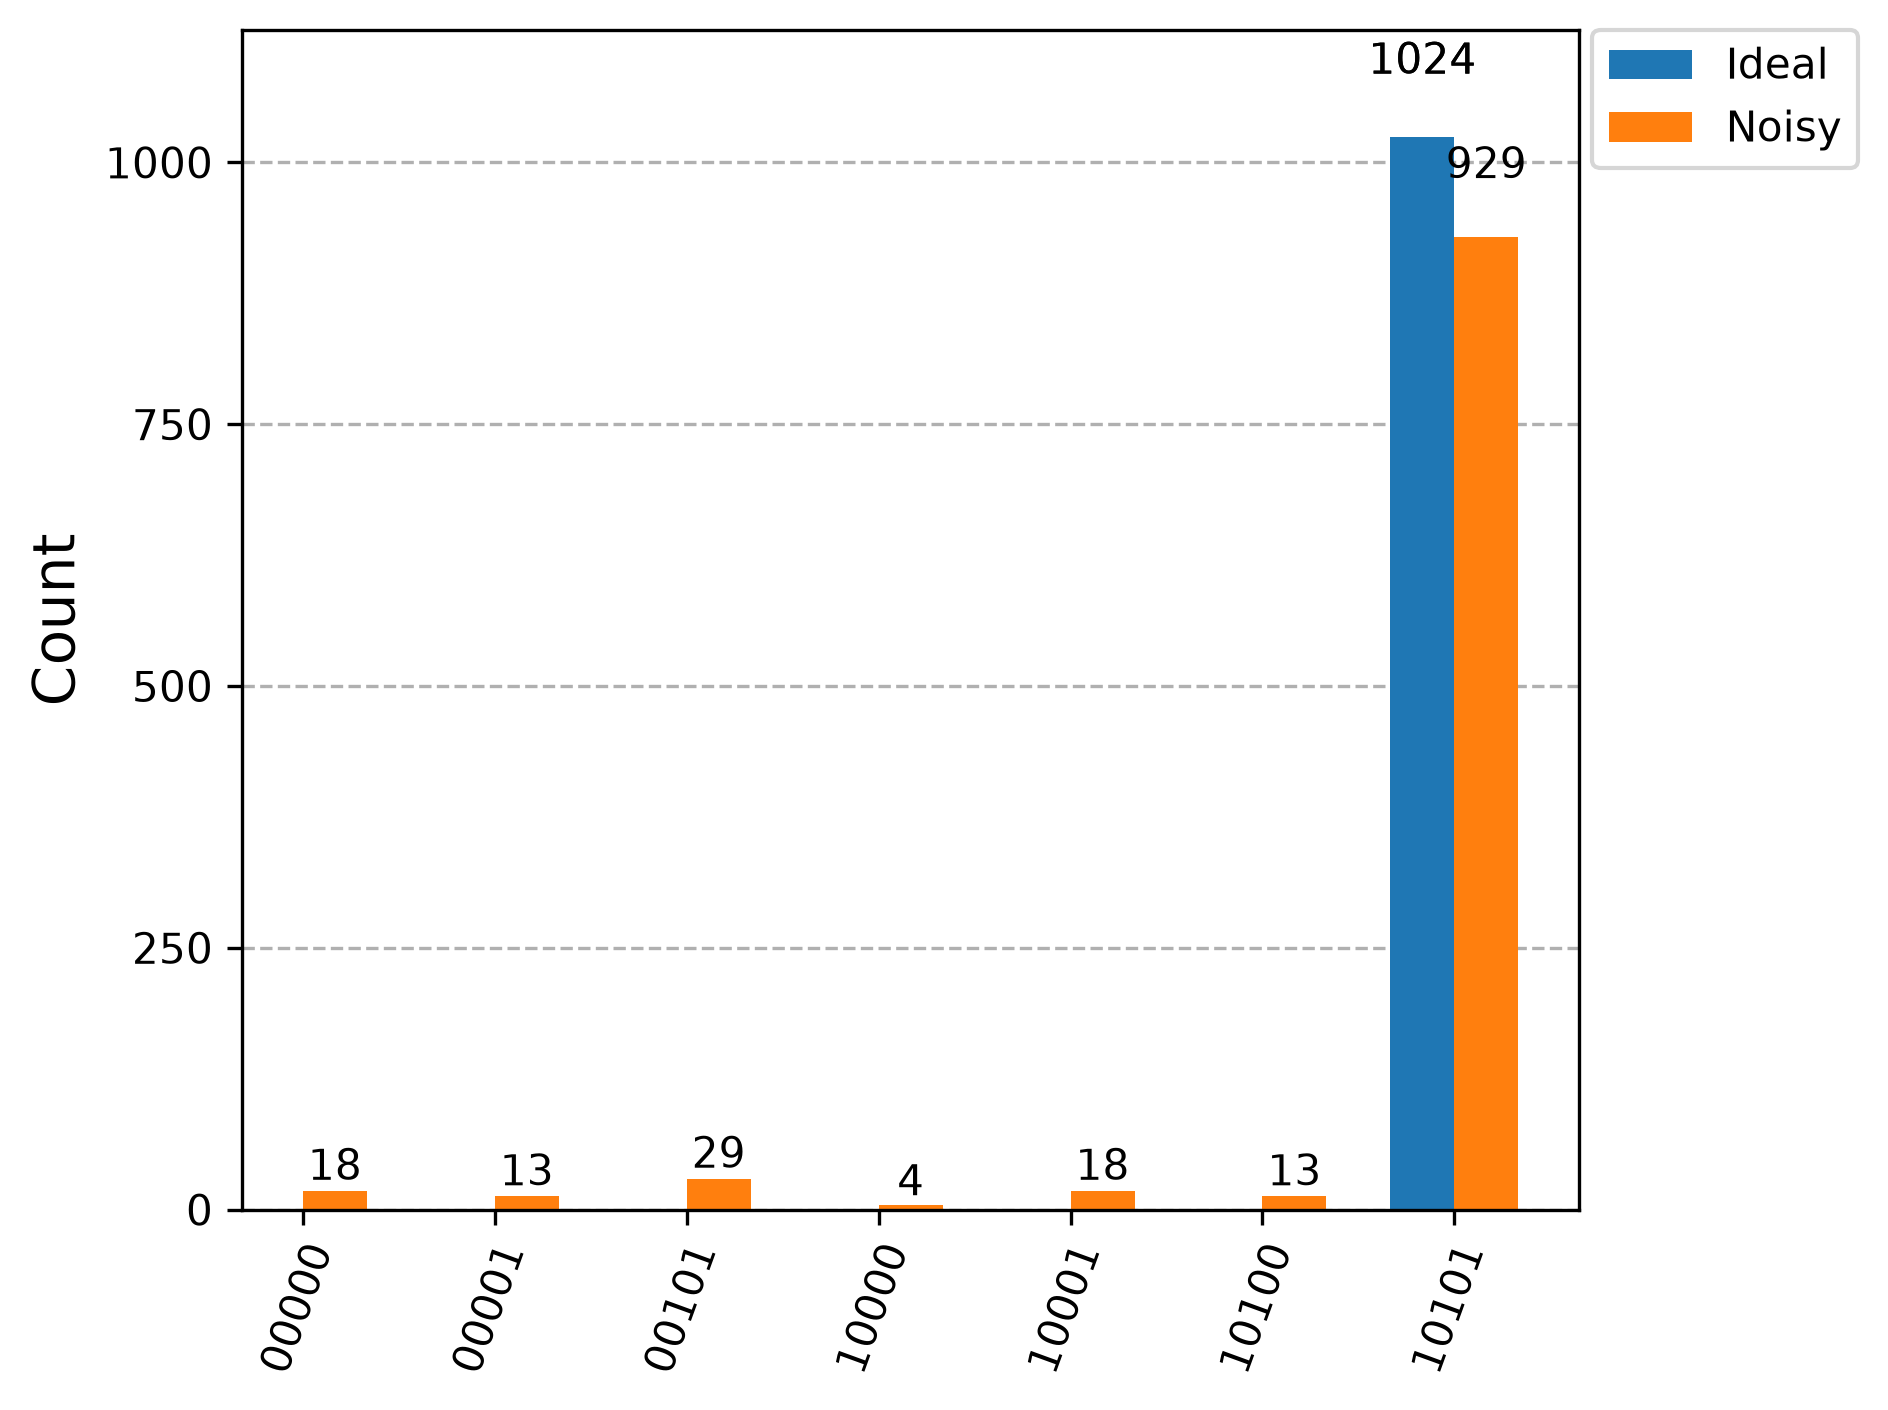

In [8]:
# Noise model
noise_model = NoiseModel()
error_1q = depolarizing_error(0.01, 1)
error_2q = depolarizing_error(0.03, 2)
noise_model.add_all_qubit_quantum_error(error_1q, ["x", "h"])
noise_model.add_all_qubit_quantum_error(error_2q, ["cx"])

ideal_backend = AerSimulator()
noisy_backend = AerSimulator(noise_model=noise_model)

# Hidden string example from the manual
s = "10101"
qc = bv_circuit(s)
ideal_counts = ideal_backend.run(
    transpile(qc, ideal_backend), shots=1024
).result().get_counts()
noisy_counts = noisy_backend.run(
    transpile(qc, noisy_backend), shots=1024
).result().get_counts()
print("Ideal:", ideal_counts)
print("Noisy:", noisy_counts)
display(plot_histogram([ideal_counts, noisy_counts],
                       legend=["Ideal", "Noisy"]))

In [9]:
# Scaling with the number of input bits
print("n  qubits  depth  gates  ideal acc  noisy acc")
for n in range(2, 7):
    s = "110101"[:n]
    qc = bv_circuit(s)
    compiled = transpile(qc, noisy_backend)
    ideal = ideal_backend.run(
        transpile(qc, ideal_backend), shots=1024
    ).result().get_counts()
    noisy = noisy_backend.run(compiled, shots=1024).result().get_counts()
    print(f"{n}  {n + 1:>6}  {compiled.depth():>5}  {compiled.size():>5}",
          f"  {ideal.get(s, 0) / 1024:>9.3f}  {noisy.get(s, 0) / 1024:>9.3f}")

n  qubits  depth  gates  ideal acc  noisy acc


2       3      6     10       1.000      0.936


3       4      6     11       1.000      0.930


4       5      7     15       1.000      0.916


5       6      7     16       1.000      0.913


6       7      8     20       1.000      0.856


In [10]:
# Effect of transpiler optimisation on the n = 6 circuit
qc = bv_circuit("110101")
for level in [0, 1, 2, 3]:
    compiled = transpile(qc, noisy_backend, optimization_level=level)
    noisy = noisy_backend.run(compiled, shots=1024).result().get_counts()
    print(f"optimization_level={level}: depth {compiled.depth()},",
          f"gates {compiled.size()},",
          f"noisy accuracy {noisy.get('110101', 0) / 1024:.3f}")

optimization_level=0: depth 8, gates 24, noisy accuracy 0.845
optimization_level=1: depth 8, gates 20, noisy accuracy 0.891


optimization_level=2: depth 8,

 gates 20, noisy accuracy 0.864
optimization_level=3: depth 8, gates 20, noisy accuracy 0.893


### Observation

The ideal simulator recovers the string on **every shot for every $n$**. Under noise the accuracy falls as $n$ grows, because each extra input bit adds another H pair and, when the bit is 1, another noisy CX, so the circuit depth and gate count rise and more shots pick up at least one error. The correct string nevertheless stays the **most frequent outcome** at every size tested, so the string can still be read off from the histogram peak. Transpiler optimisation barely changes this circuit: it is already made of basis gates, so all levels give nearly the same depth and accuracy.

## Conclusion

The Bernstein-Vazirani algorithm recovered hidden strings of every length tested with one oracle query, where the classical approach needs one query per bit. The mechanism is phase kickback through an ancilla in |->, which the final Hadamard layer converts into the string itself; any other ancilla preparation breaks the algorithm. Noise lowers the success probability as the circuit grows, but the hidden string remained the dominant outcome up to six bits, and the oracle is defined by its unitary rather than by one particular arrangement of CX gates.